### Step 1: Load and Inspect Your 6-Column CSV

In your first notebook cell, load your CSV, check the columns, and merge the text into a single target column:

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

In [15]:
# 1. Load your collected data
df = pd.read_csv('data/scouting_corpus_30.csv')

In [16]:
# 2. Fill empty values across your text sections
text_cols = ['overview', 'strengths', 'weaknesses']
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].fillna('')

In [17]:
# 3. Combine sections into one unified text field
df['evaluation_text'] = (
    df['overview'] + ' ' + df['strengths'] + ' ' + df['weaknesses']
).str.strip()

In [18]:
print(f"Total profiles loaded: {len(df)}")
print("\nCohort Breakdown:")
print(df['demographic_group'].value_counts())
df[['player_name', 'demographic_group', 'draft_year']].head()

Total profiles loaded: 30

Cohort Breakdown:
demographic_group
Black    15
white    15
Name: count, dtype: int64


,player_name,demographic_group,draft_year
0,Lamar Jackson,Black,2018
1,Patrick Mahomes,Black,2017
2,C.J. Stroud,Black,2023
3,Jayden Daniels,Black,2024
4,Anthony Richardson,Black,2023


### Step 2: TF-IDF Extraction and Cohort Divergence

This block tokenizes single words and two-word phrases, filters out standard football terms that scouts use for everyone (so they don't dominate the results), and calculates which terms uniquely separate the cohorts:

In [19]:
# Custom sports + resume + metadata noise
base_stopwords = list(TfidfVectorizer(stop_words='english').get_stop_words())
custom_noise = [
    'quarterback', 'qb', 'player', 'football', 'offense', 'game', 'play', 
    'plays', 'film', 'season', 'throw', 'throws', 'throwing', 'pass', 
    'passer', 'passing', 'ball', 'level', 'make', 'makes', 'need', 'needs',
    'grade', 'draft', 'overall', 'good', 'ability', 'shows', 'look', 'looks',
    'times', 'variety', 'average', 'year', 'starter', 'year starter'
]
metadata_noise = [
    '2020', '2021', '2022', '2023', '2024', '2025', 
    'college', 'career', 'starts', 'started', 'games', 'round'
]
all_stopwords = base_stopwords + custom_noise + metadata_noise

# TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    stop_words=all_stopwords,
    ngram_range=(1, 2),
    token_pattern=r'(?u)\b[a-zA-Z]{3,}\b',
    min_df=2,
    max_features=150
)

tfidf_matrix = tfidf.fit_transform(df['evaluation_text'])
features = tfidf.get_feature_names_out()

tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=features)
tfidf_df['demographic_group'] = df['demographic_group'].values

group_means = tfidf_df.groupby('demographic_group').mean().T
groups = [c for c in group_means.columns if c != 'demographic_group']

# Calculate relative divergence
group_means['divergence'] = group_means[groups[0]] - group_means[groups[1]]

### Step 3: Generate the Comparative Visual

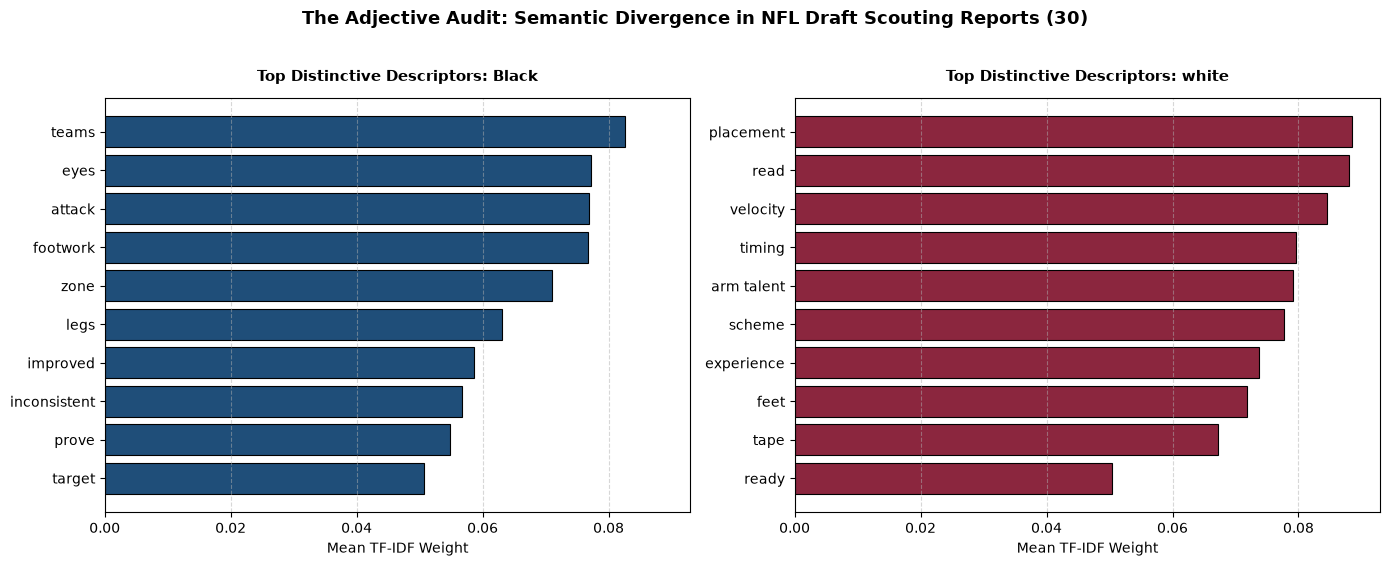

In [21]:
# Isolate top 10 divergent terms
top_group_0 = group_means.sort_values(by='divergence', ascending=False).head(10)
top_group_1 = group_means.sort_values(by='divergence', ascending=True).head(10)

# Sort each group individually by its own weight so bars are neat and descending
plot_g0 = top_group_0.sort_values(by=groups[0], ascending=True)
plot_g1 = top_group_1.sort_values(by=groups[1], ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)

# Cohort 1
axes[0].barh(plot_g0.index, plot_g0[groups[0]], color='#1f4e79', edgecolor='black', linewidth=0.8)
axes[0].set_title(f"Top Distinctive Descriptors: {groups[0]}", fontsize=11, fontweight='bold', pad=12)
axes[0].set_xlabel('Mean TF-IDF Weight')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Cohort 2
axes[1].barh(plot_g1.index, plot_g1[groups[1]], color='#8b263e', edgecolor='black', linewidth=0.8)
axes[1].set_title(f"Top Distinctive Descriptors: {groups[1]}", fontsize=11, fontweight='bold', pad=12)
axes[1].set_xlabel('Mean TF-IDF Weight')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle("The Adjective Audit: Semantic Divergence in NFL Draft Scouting Reports (30)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()